# Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Read data

In [2]:
df=pd.read_csv('/content/healthcare-dataset-stroke-data.csv')

In [3]:
df.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')

| العمود              | الوصف                                                                 |
| ------------------- | --------------------------------------------------------------------- |
| `id`                | رقم تعريفي فريد لكل شخص.                                              |
| `gender`            | جنس الشخص، مثل Male / Female / Other.                                 |
| `age`               | عمر الشخص بالسنوات.                                                   |
| `hypertension`      | هل الشخص يعاني من ارتفاع ضغط الدم؟ `1 = نعم`، `0 = لا`.               |
| `heart_disease`     | هل الشخص يعاني من أمراض القلب؟ `1 = نعم`، `0 = لا`.                   |
| `ever_married`      | هل الشخص سبق له الزواج؟ `Yes / No`.                                   |
| `work_type`         | نوع العمل، مثل Private أو Self-employed أو Government Job أو الأطفال. |
| `Residence_type`    | نوع مكان الإقامة: Urban أو Rural.                                     |
| `avg_glucose_level` | متوسط مستوى الجلوكوز في الدم.                                         |
| `bmi`               | مؤشر كتلة الجسم **BMI**.                                              |
| `smoking_status`    | حالة التدخين، مثل formerly smoked / never smoked / smokes / Unknown.  |
| `stroke`            | **Target**: هل أصيب الشخص بسكتة دماغية؟ `1 = نعم`، `0 = لا`.          |


In [4]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [6]:
df.shape

(5110, 12)

# Remove Column


In [7]:
df.drop(['id'],axis=1,inplace=True)


In [8]:
# Dropping the duplicate rows
print("Number of duplicate rows : ",df.duplicated().sum())

Number of duplicate rows :  0


# Data Cleaning
missing Value

In [9]:
df.isnull().sum().sort_values(ascending = False).head(8)

,0
bmi,201
age,0
gender,0
hypertension,0
heart_disease,0
work_type,0
ever_married,0
Residence_type,0


#Replace Nan value

<Axes: xlabel='bmi', ylabel='Count'>

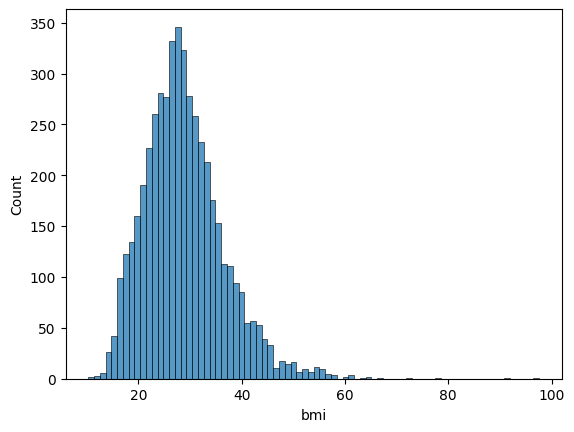

In [10]:
sns.histplot(df['bmi'])

In [11]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values=np.nan, strategy='median')
imputer.fit(df[['bmi']])
df['bmi'] = imputer.transform(df[['bmi']])

In [12]:
df.isnull().sum().sum()

np.int64(0)

#Data Encoding

In [13]:
for col in df.select_dtypes(include=['object']).columns:
    print(f'number of column {col} is : ',df[col].nunique())
    print(f'number of column {col} is : ',df[col].unique())

number of column gender is :  3
number of column gender is :  ['Male' 'Female' 'Other']
number of column ever_married is :  2
number of column ever_married is :  ['Yes' 'No']
number of column work_type is :  5
number of column work_type is :  ['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']
number of column Residence_type is :  2
number of column Residence_type is :  ['Urban' 'Rural']
number of column smoking_status is :  4
number of column smoking_status is :  ['formerly smoked' 'never smoked' 'smokes' 'Unknown']


In [14]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

for col in ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']:
    df[col] = le.fit_transform(df[col])

df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,67.0,0,1,1,2,1,228.69,36.6,1,1
1,0,61.0,0,0,1,3,0,202.21,28.1,2,1
2,1,80.0,0,1,1,2,0,105.92,32.5,2,1
3,0,49.0,0,0,1,2,1,171.23,34.4,3,1
4,0,79.0,1,0,1,3,0,174.12,24.0,2,1


# Outliers

{'whiskers': [<matplotlib.lines.Line2D at 0x7c8f9c4c2fd0>,
 'caps': [<matplotlib.lines.Line2D at 0x7c8f9c4c3250>,
 'boxes': [<matplotlib.lines.Line2D at 0x7c8f9c4c2e90>],
 'medians': [<matplotlib.lines.Line2D at 0x7c8f9c4c34d0>],
 'fliers': [<matplotlib.lines.Line2D at 0x7c8f9c4c3610>],
 'means': []}

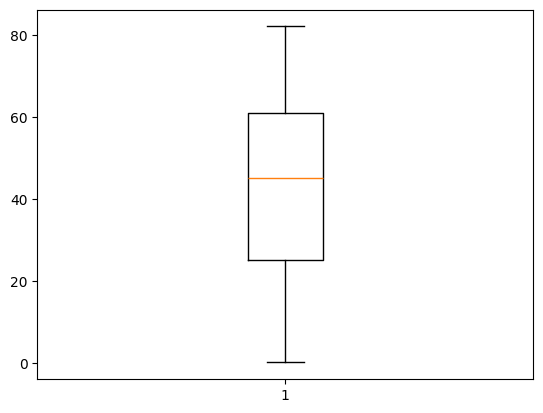

In [15]:
plt.boxplot(df['age'])

{'whiskers': [<matplotlib.lines.Line2D at 0x7c8f9c51e0d0>,
 'caps': [<matplotlib.lines.Line2D at 0x7c8f9c51e350>,
 'boxes': [<matplotlib.lines.Line2D at 0x7c8f9c51df90>],
 'medians': [<matplotlib.lines.Line2D at 0x7c8f9c51e5d0>],
 'fliers': [<matplotlib.lines.Line2D at 0x7c8f9c51e710>],
 'means': []}

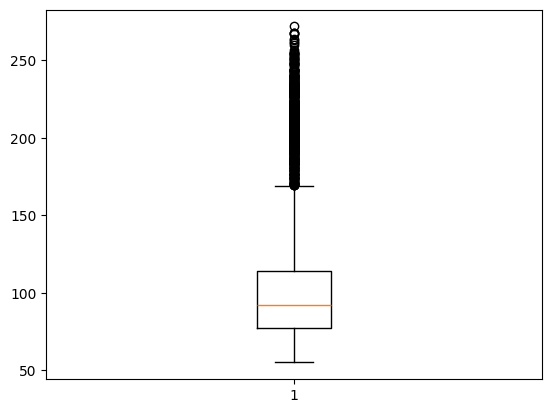

In [16]:
plt.boxplot(df['avg_glucose_level'])

In [17]:
def remove_outliers_iqr(data, column_name="value"):
    Q1 = df[column_name].quantile(0.25)
    Q3 = df[column_name].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return df[(df[column_name] >= lower) & (df[column_name] <= upper)]
cleaned_df = remove_outliers_iqr(df, column_name="avg_glucose_level")

print(df.shape,cleaned_df.shape)

(5110, 11) (4483, 11)


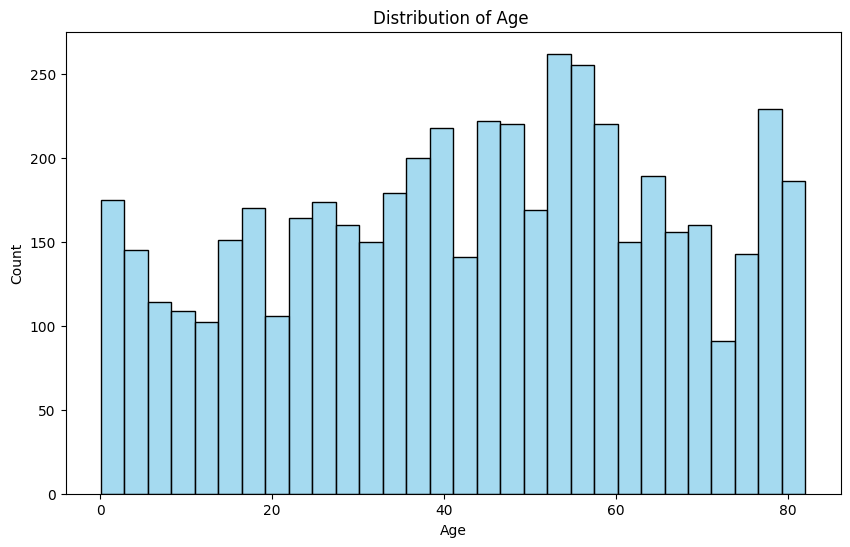

In [18]:


plt.figure(figsize=(10, 6))
sns.histplot(df['age'],  color='skyblue', bins=30)
plt.title('Distribution of Age ')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

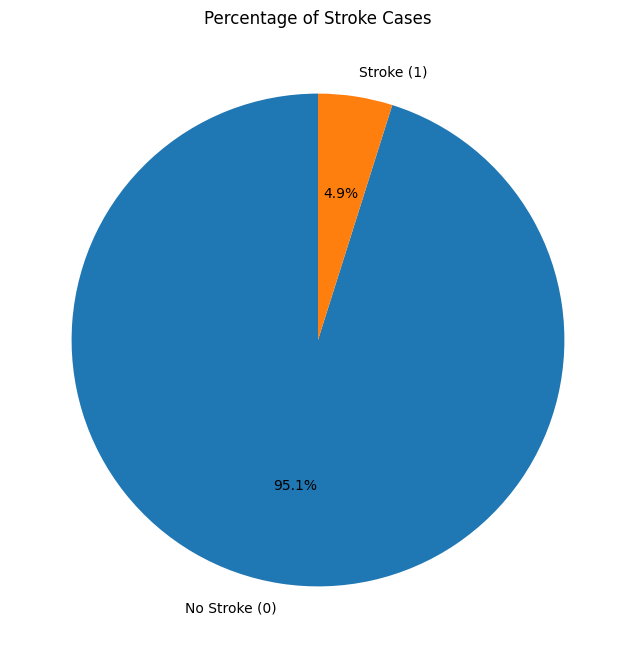

In [19]:
plt.figure(figsize=(8, 8))
stroke_counts = df['stroke'].value_counts()
plt.pie(stroke_counts, labels=['No Stroke (0)', 'Stroke (1)'], autopct='%1.1f%%', startangle=90)
plt.title('Percentage of Stroke Cases')
plt.show()

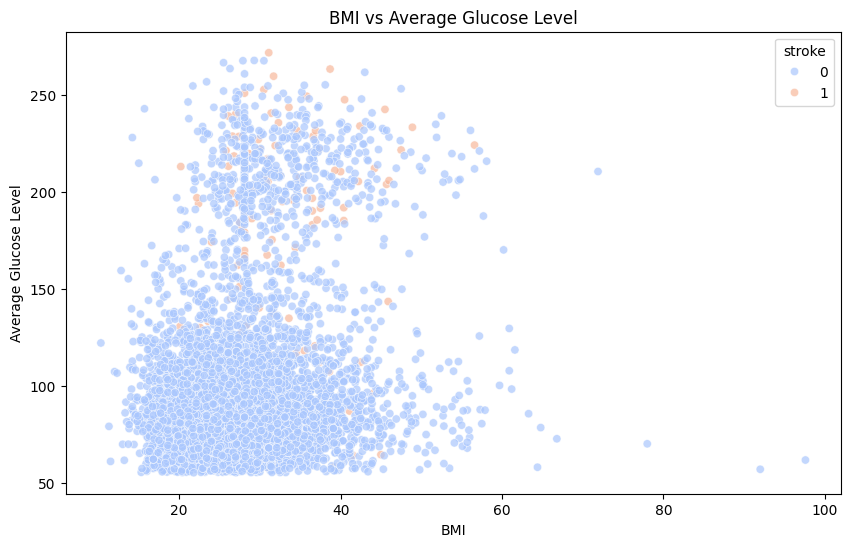

In [20]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='bmi', y='avg_glucose_level', hue='stroke', palette='coolwarm', alpha=0.7)
plt.title('BMI vs Average Glucose Level')
plt.xlabel('BMI')
plt.ylabel('Average Glucose Level')
plt.show()

/tmp/ipykernel_1353/3071726637.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='smoking_status', y='stroke', palette='muted', errorbar=None)


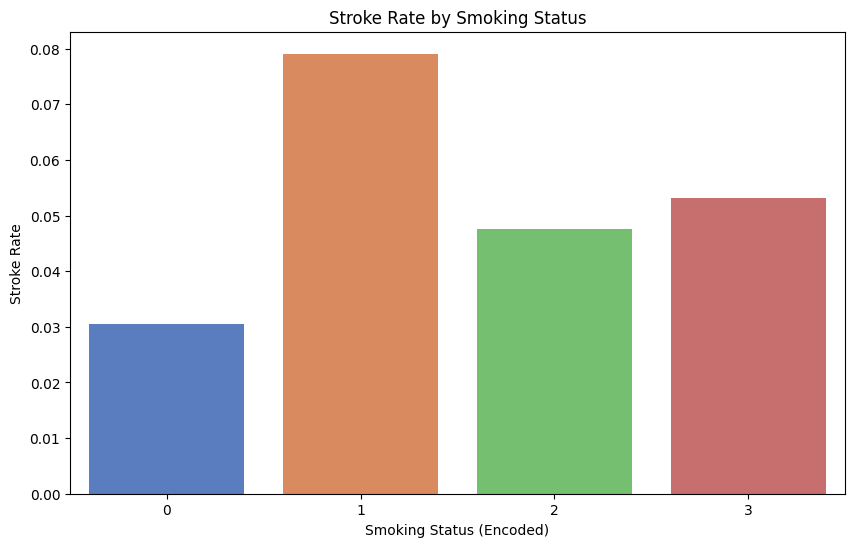

In [21]:
plt.figure(figsize=(10, 6))
sns.barplot(data=df, x='smoking_status', y='stroke', palette='muted', errorbar=None)
plt.title('Stroke Rate by Smoking Status')
plt.xlabel('Smoking Status (Encoded)')
plt.ylabel('Stroke Rate')
plt.show()

/tmp/ipykernel_1353/3827467227.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='work_type', y='bmi', palette='Set2')


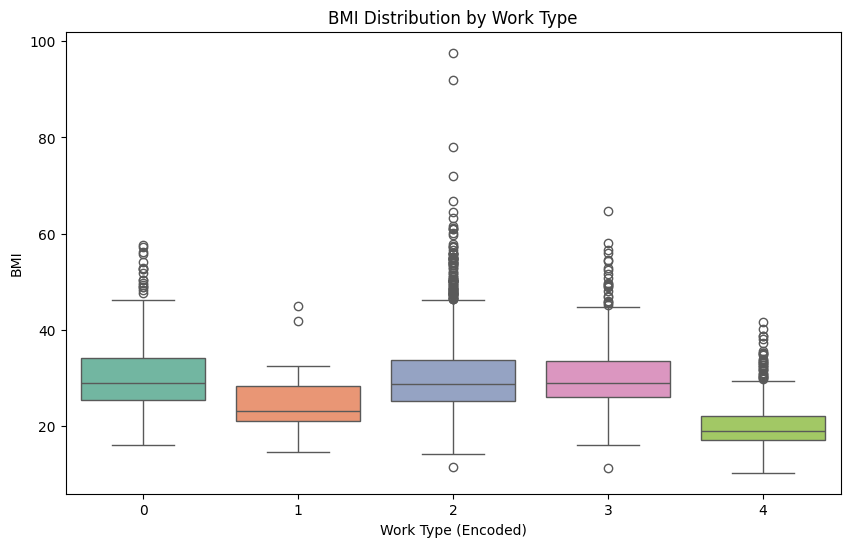

In [22]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='work_type', y='bmi', palette='Set2')
plt.title('BMI Distribution by Work Type')
plt.xlabel('Work Type (Encoded)')
plt.ylabel('BMI')
plt.show()

In [23]:
X=df.drop('stroke',axis=1)
y=df['stroke']

In [24]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [25]:
from sklearn.linear_model import LogisticRegression


In [26]:
model=LogisticRegression(
    penalty='l2',
    C=1.0,
    solver='liblinear',
    max_iter=200
)

In [27]:
model=model.fit(X_train,y_train)

In [28]:
y_pred=model.predict(X_test)

In [29]:
y_pred,y_test

(array([0, 0, 0, ..., 0, 0, 0]),
 4688    0
 4478    0
 3849    0
 4355    0
 3826    0
        ..
 3605    0
 4934    0
 4835    0
 4105    0
 2902    0
 Name: stroke, Length: 1022, dtype: int64)

In [30]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
print(accuracy_score(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred))

0.9393346379647749
[[960   0]
 [ 62   0]]
              precision    recall  f1-score   support

           0       0.94      1.00      0.97       960
           1       0.00      0.00      0.00        62

    accuracy                           0.94      1022
   macro avg       0.47      0.50      0.48      1022
weighted avg       0.88      0.94      0.91      1022



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


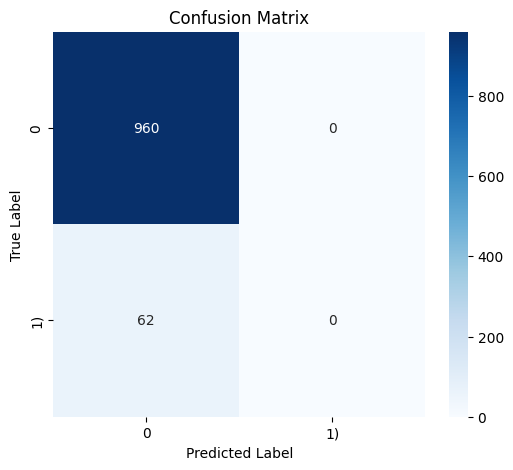

In [31]:
cm=confusion_matrix(y_test,y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['0', '1)'],
            yticklabels=['0', '1)'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [32]:
from sklearn.neighbors import KNeighborsClassifier
model=KNeighborsClassifier(n_neighbors=5,metric='minkowski')
model=model.fit(X_train,y_train)
y_pred=model.predict(X_test)
y_pred_test=model.predict(X_train)
acc_train=accuracy_score(y_train,y_pred_test)
acc_test=accuracy_score(y_test,y_pred)
print(acc_train,acc_test)

0.9554794520547946 0.9354207436399217


In [33]:
from sklearn.metrics import precision_score, recall_score, f1_score

results = []

# Logistic Regression
model = LogisticRegression(max_iter=1000) # Increased max_iter to prevent convergence warning
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

results.append({
    'Method': "Normal Data",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [34]:
from imblearn.under_sampling import RandomUnderSampler
rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)
print("X_train_rus = ",X_train_rus.shape ," y_train_rus = ", y_train_rus.shape)

X_train_rus =  (374, 10)  y_train_rus =  (374,)


In [35]:
y_train_rus.value_counts()

,count
stroke,
0,187
1,187


In [36]:
model = LogisticRegression()
model.fit(X_train_rus, y_train_rus)
y_pred = model.predict(X_test)

results.append({
    'Method': "SMOTE Over Sampling",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [37]:
model = LogisticRegression(class_weight='balanced')
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

results.append({
    'Method': "Class Weight Balanced",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [38]:
model = LogisticRegression(class_weight={0:1,1:10})
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

results.append({
    'Method': "Class Weight Balanced Custom",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [39]:
np.unique(y_train)

array([0, 1])

In [40]:
results_df = pd.DataFrame(results).set_index('Method')
results_df

,Accuracy,Precision,Recall,F1-Score
Method,,,,
Normal Data,0.939335,0.000000,0.000000,0.000000
SMOTE Over Sampling,0.736791,0.156146,0.758065,0.258953
Class Weight Balanced,0.749511,0.163194,0.758065,0.268571
Class Weight Balanced Custom,0.856164,0.229299,0.580645,0.328767


In [42]:
pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 33.5 MB/s  0:00:02


In [43]:
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


In [44]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[960   0]
 [ 62   0]]


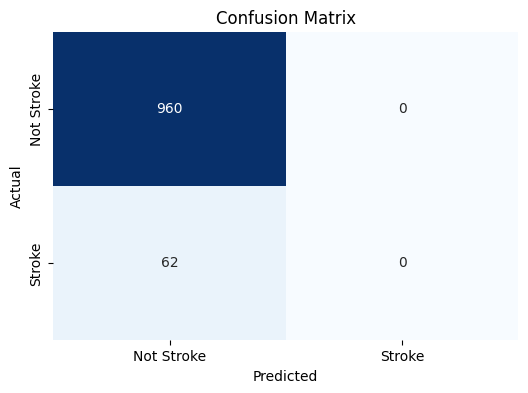


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.94      1.00      0.97       960
      Stroke       0.00      0.00      0.00        62

    accuracy                           0.94      1022
   macro avg       0.47      0.50      0.48      1022
weighted avg       0.88      0.94      0.91      1022

ROC-AUC: 0.8512600806451612


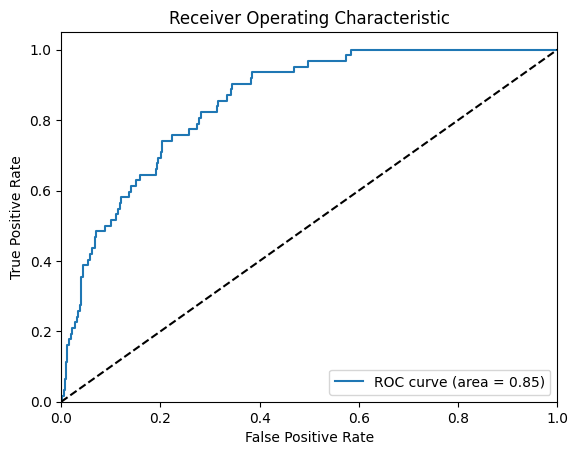

PR AUC: 0.2632166547612686


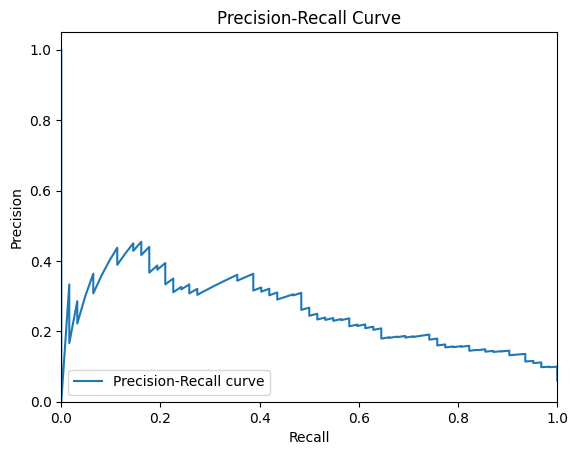

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
  8%|▊         | 1/13 [00:01<00:20,  1.73s/it]


Confusion Matrix:
 [[955   5]
 [ 61   1]]


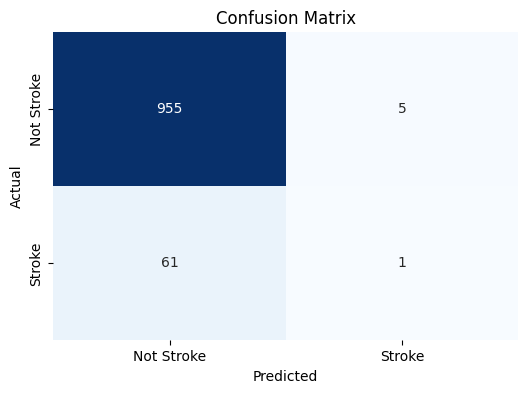


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.94      0.99      0.97       960
      Stroke       0.17      0.02      0.03        62

    accuracy                           0.94      1022
   macro avg       0.55      0.51      0.50      1022
weighted avg       0.89      0.94      0.91      1022

ROC-AUC: 0.6658686155913979


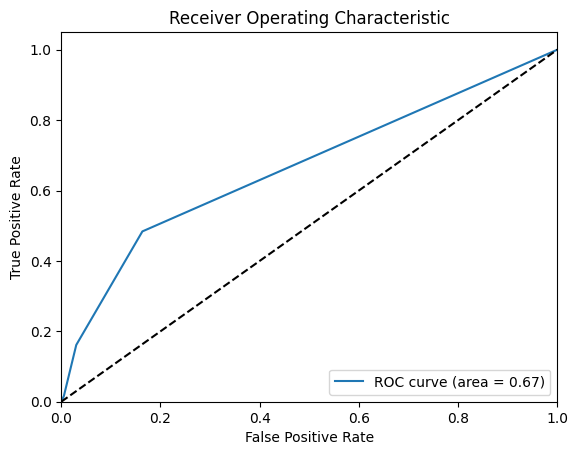

PR AUC: 0.12297107595514187


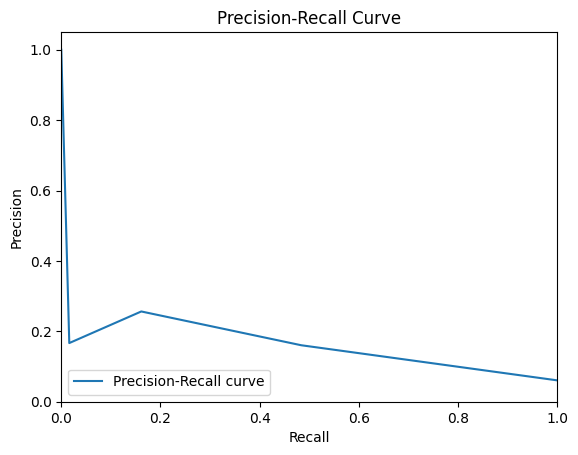

 15%|█▌        | 2/13 [00:04<00:25,  2.30s/it]


Confusion Matrix:
 [[960   0]
 [ 62   0]]


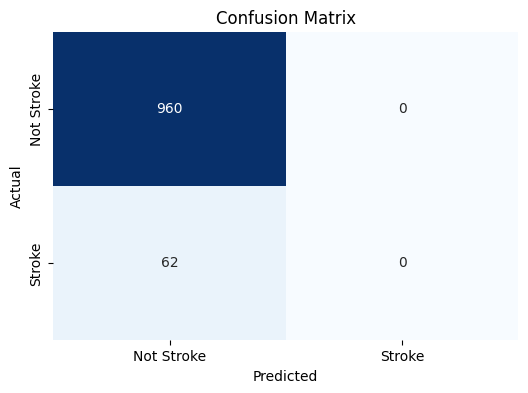


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.94      1.00      0.97       960
      Stroke       0.00      0.00      0.00        62

    accuracy                           0.94      1022
   macro avg       0.47      0.50      0.48      1022
weighted avg       0.88      0.94      0.91      1022

ROC-AUC: 0.5729670698924731


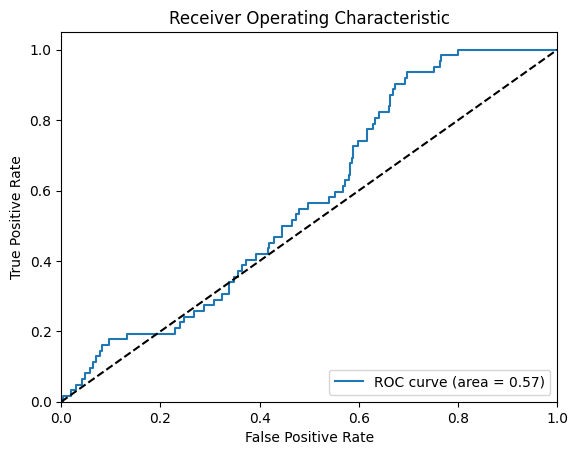

PR AUC: 0.07703077689774984


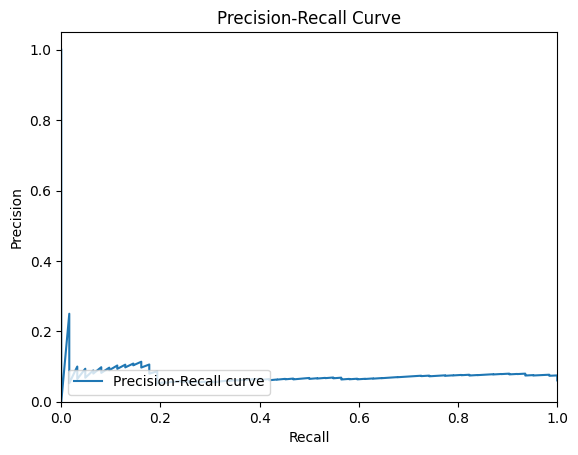

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
 23%|██▎       | 3/13 [00:08<00:30,  3.06s/it]


Confusion Matrix:
 [[913  47]
 [ 53   9]]


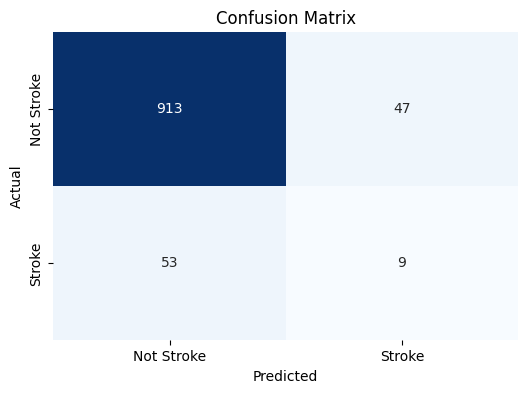


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.95      0.95      0.95       960
      Stroke       0.16      0.15      0.15        62

    accuracy                           0.90      1022
   macro avg       0.55      0.55      0.55      1022
weighted avg       0.90      0.90      0.90      1022

ROC-AUC: 0.5481014784946237


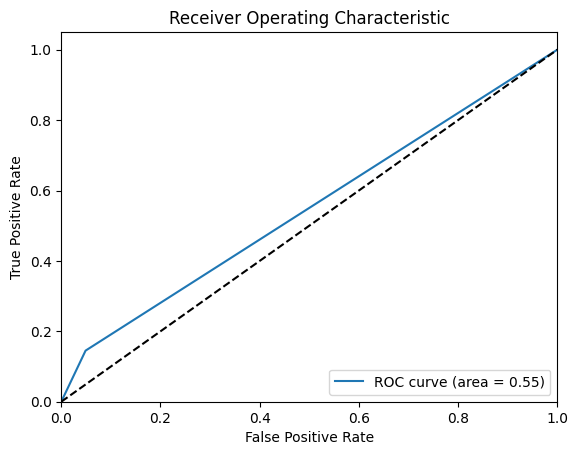

PR AUC: 0.07518859289186289


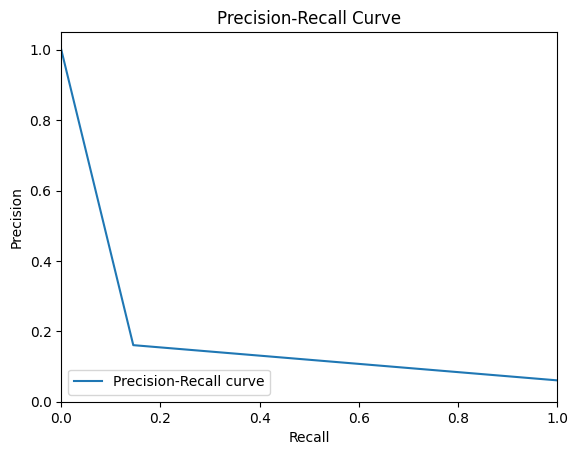

 31%|███       | 4/13 [00:09<00:21,  2.42s/it]


Confusion Matrix:
 [[858 102]
 [ 33  29]]


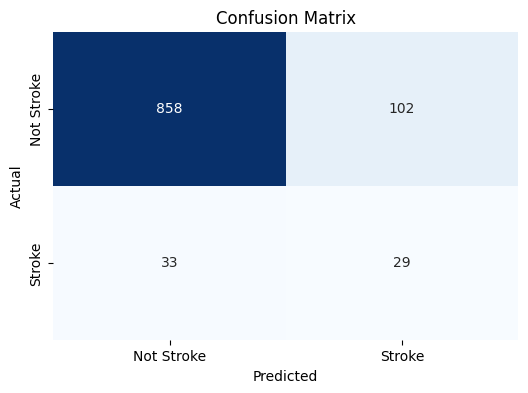


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.96      0.89      0.93       960
      Stroke       0.22      0.47      0.30        62

    accuracy                           0.87      1022
   macro avg       0.59      0.68      0.61      1022
weighted avg       0.92      0.87      0.89      1022

ROC-AUC: 0.8288474462365591


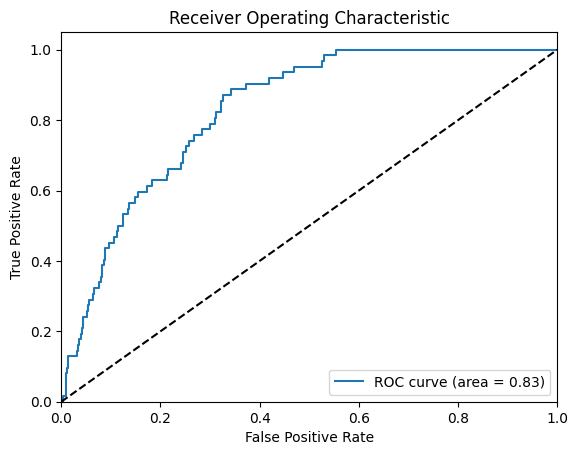

PR AUC: 0.20273029098140452


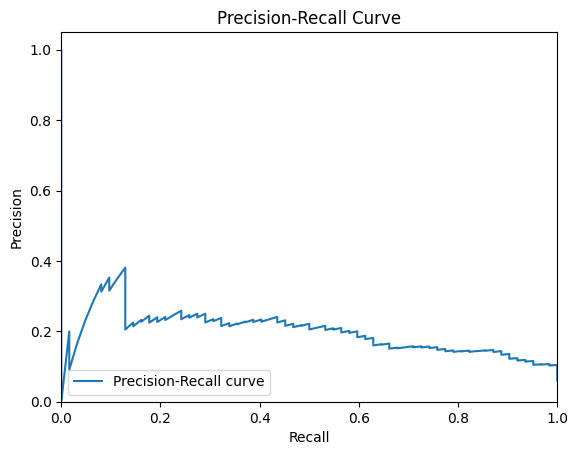

 38%|███▊      | 5/13 [00:11<00:17,  2.13s/it]


Confusion Matrix:
 [[960   0]
 [ 61   1]]


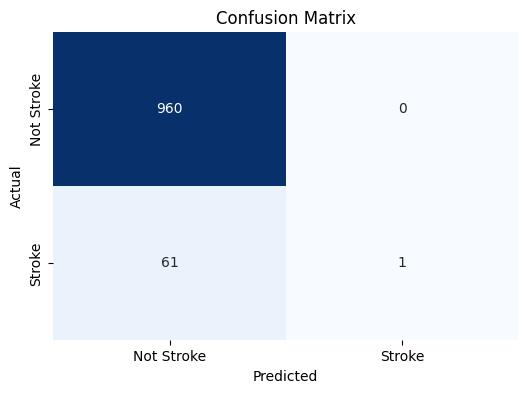


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.94      1.00      0.97       960
      Stroke       1.00      0.02      0.03        62

    accuracy                           0.94      1022
   macro avg       0.97      0.51      0.50      1022
weighted avg       0.94      0.94      0.91      1022

ROC-AUC: 0.826419690860215


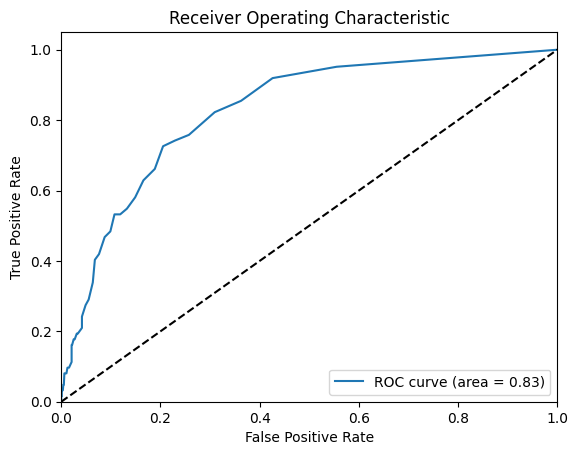

PR AUC: 0.24157683887272413


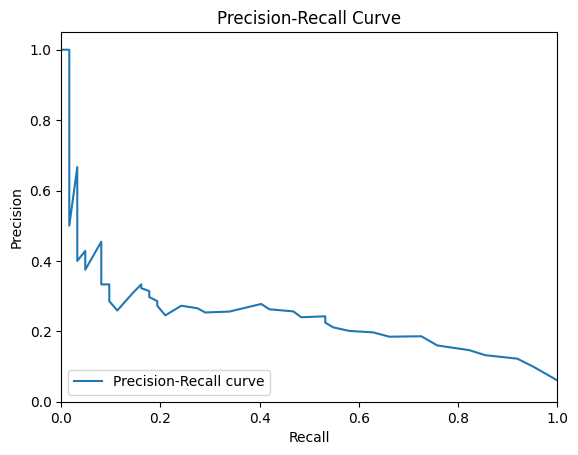

 46%|████▌     | 6/13 [00:13<00:15,  2.23s/it]


Confusion Matrix:
 [[954   6]
 [ 61   1]]


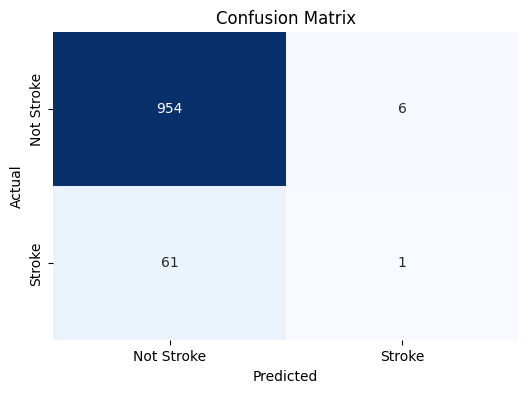


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.94      0.99      0.97       960
      Stroke       0.14      0.02      0.03        62

    accuracy                           0.93      1022
   macro avg       0.54      0.50      0.50      1022
weighted avg       0.89      0.93      0.91      1022

ROC-AUC: 0.7522597446236559


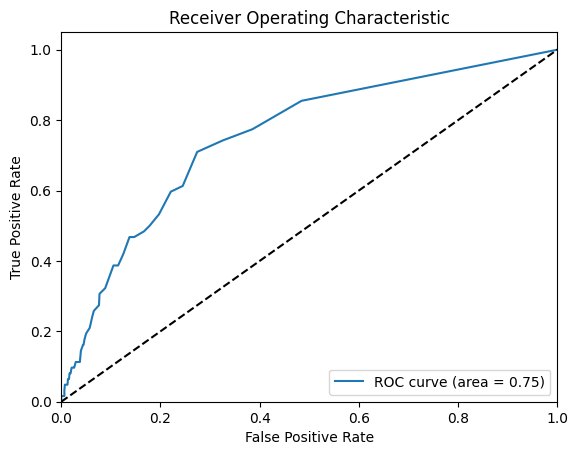

PR AUC: 0.1680173892734883


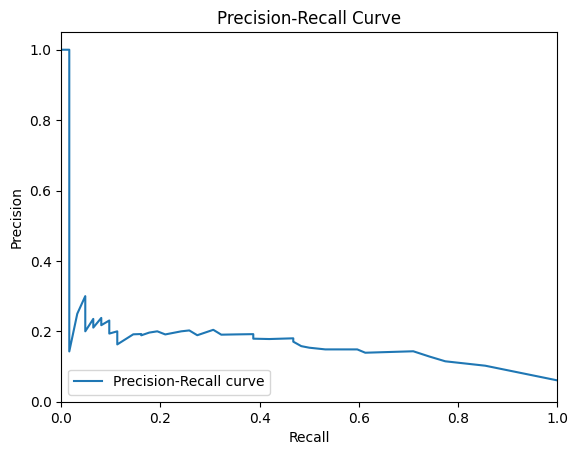

 54%|█████▍    | 7/13 [00:16<00:14,  2.49s/it]


Confusion Matrix:
 [[960   0]
 [ 62   0]]


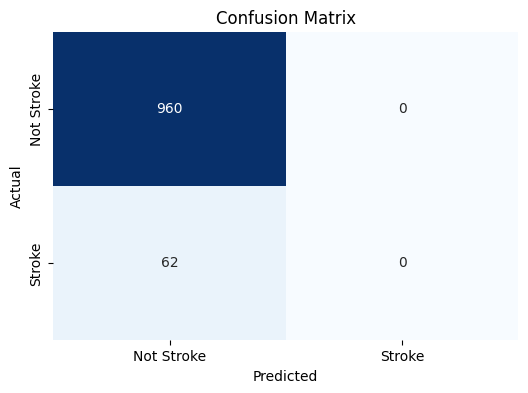


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.94      1.00      0.97       960
      Stroke       0.00      0.00      0.00        62

    accuracy                           0.94      1022
   macro avg       0.47      0.50      0.48      1022
weighted avg       0.88      0.94      0.91      1022

ROC-AUC: 0.8402217741935485


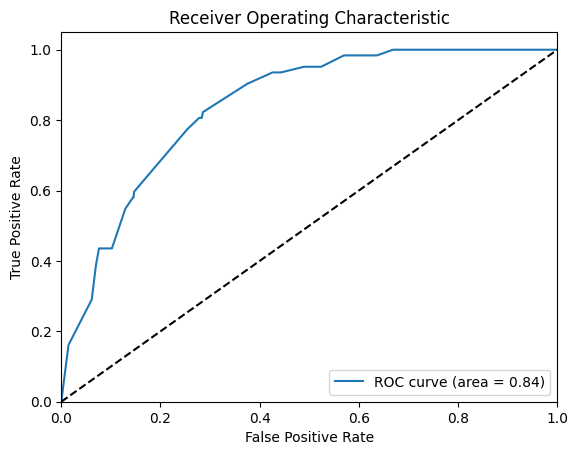

PR AUC: 0.22834136832582944


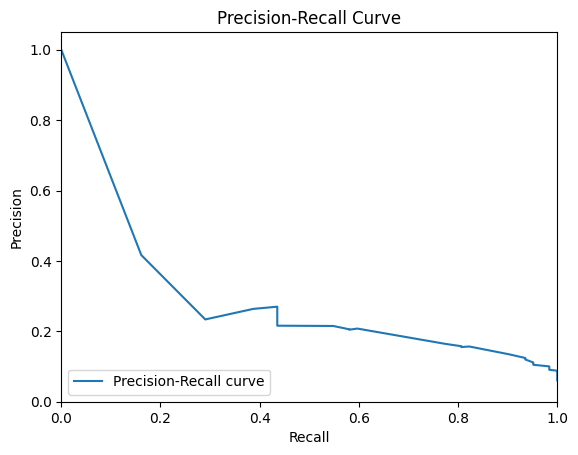

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
 62%|██████▏   | 8/13 [00:19<00:12,  2.40s/it]


Confusion Matrix:
 [[960   0]
 [ 62   0]]


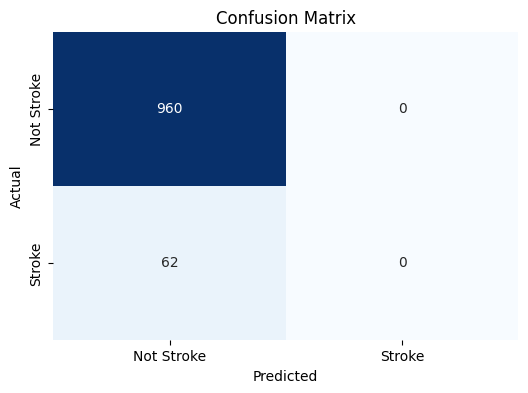


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.94      1.00      0.97       960
      Stroke       0.00      0.00      0.00        62

    accuracy                           0.94      1022
   macro avg       0.47      0.50      0.48      1022
weighted avg       0.88      0.94      0.91      1022

ROC-AUC: 0.8321992607526881


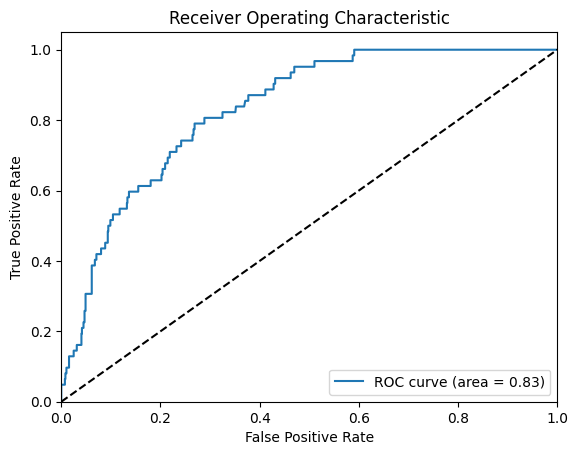

PR AUC: 0.2547939860067685


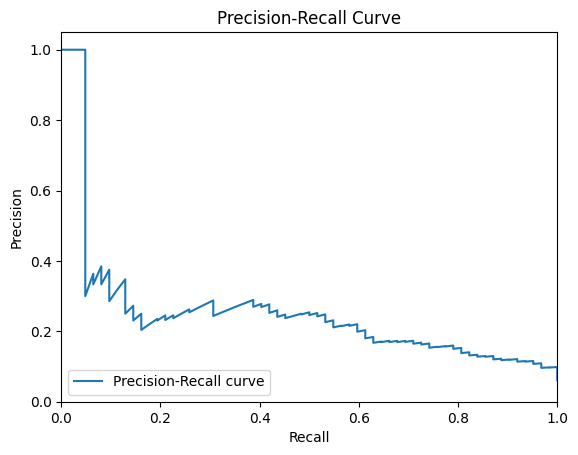

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
 69%|██████▉   | 9/13 [00:21<00:09,  2.38s/it]


Confusion Matrix:
 [[955   5]
 [ 60   2]]


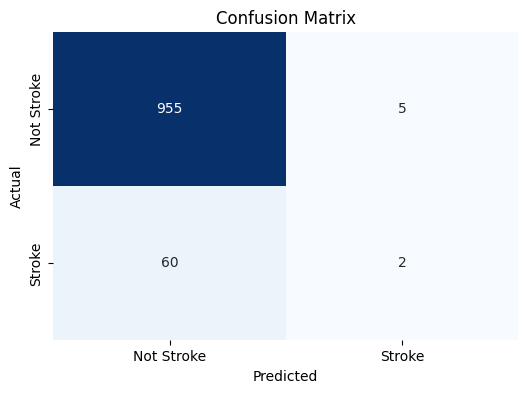


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.94      0.99      0.97       960
      Stroke       0.29      0.03      0.06        62

    accuracy                           0.94      1022
   macro avg       0.61      0.51      0.51      1022
weighted avg       0.90      0.94      0.91      1022

ROC-AUC: 0.8087533602150537


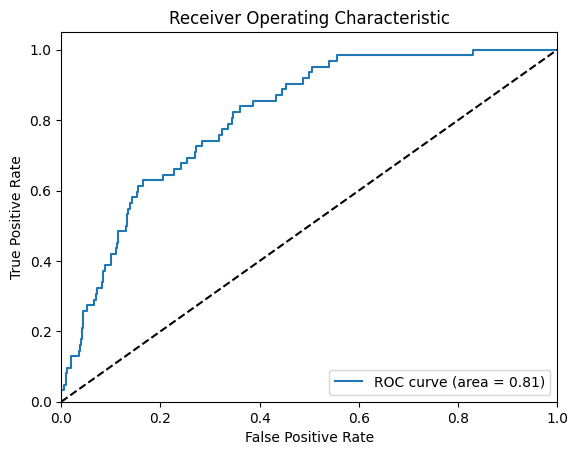

PR AUC: 0.21931599827254084


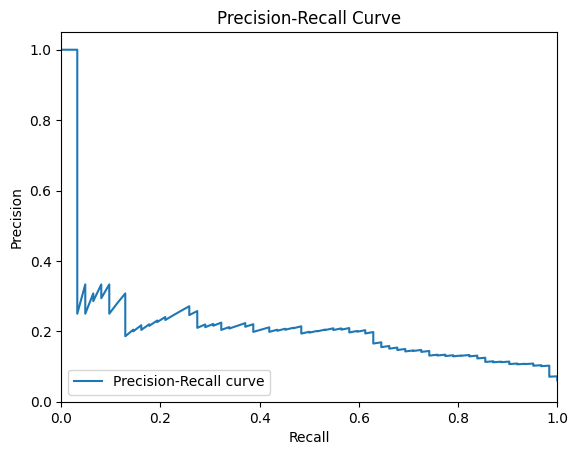

 77%|███████▋  | 10/13 [00:22<00:05,  1.89s/it]/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [16:08:56] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[951   9]
 [ 58   4]]


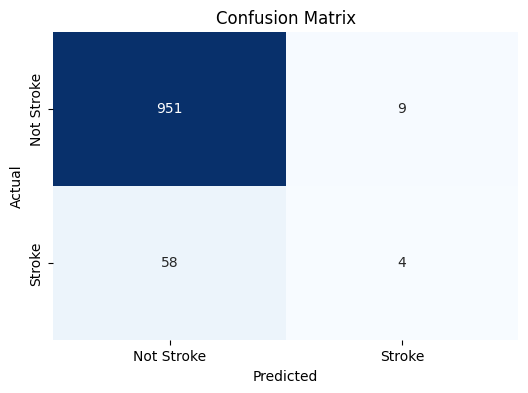


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.94      0.99      0.97       960
      Stroke       0.31      0.06      0.11        62

    accuracy                           0.93      1022
   macro avg       0.63      0.53      0.54      1022
weighted avg       0.90      0.93      0.91      1022

ROC-AUC: 0.800554435483871


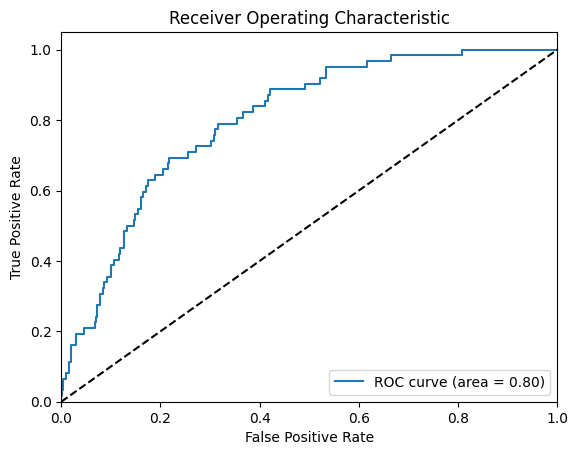

PR AUC: 0.21400696534190905


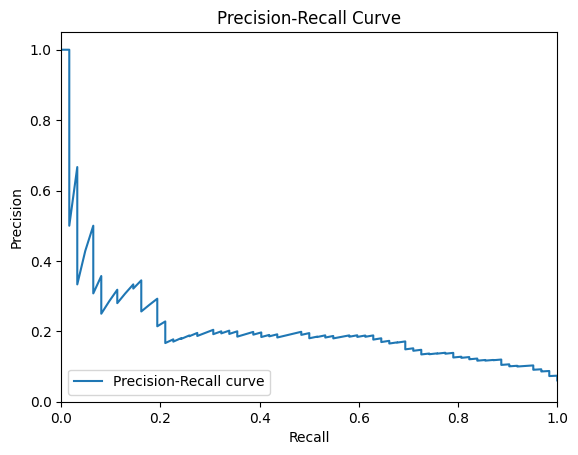

 85%|████████▍ | 11/13 [00:22<00:02,  1.50s/it]


Confusion Matrix:
 [[958   2]
 [ 61   1]]


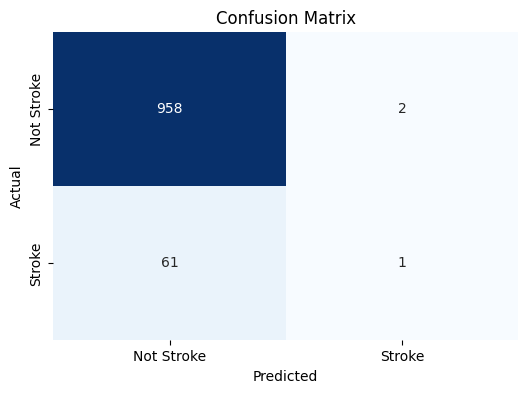


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.94      1.00      0.97       960
      Stroke       0.33      0.02      0.03        62

    accuracy                           0.94      1022
   macro avg       0.64      0.51      0.50      1022
weighted avg       0.90      0.94      0.91      1022

ROC-AUC: 0.8155073924731183


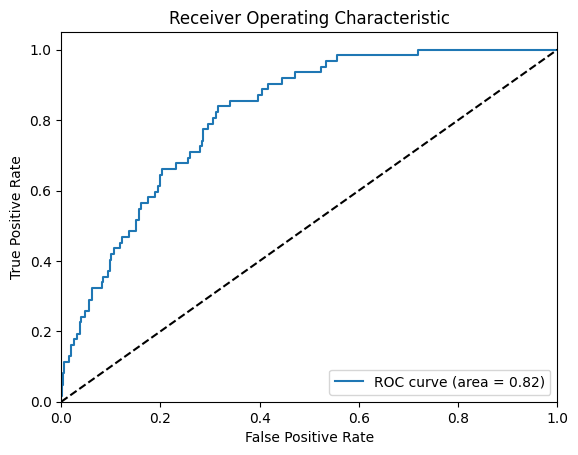

PR AUC: 0.2362764109159602


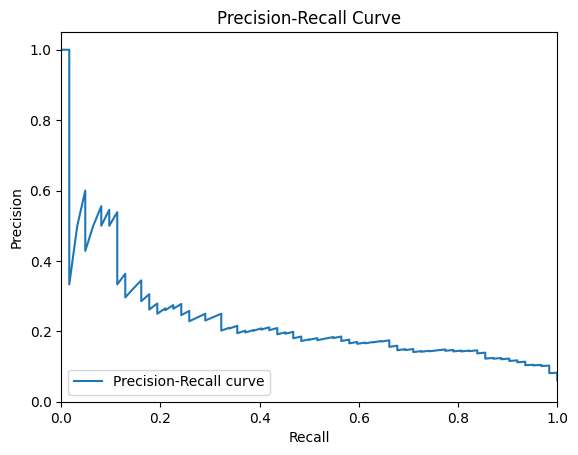

 92%|█████████▏| 12/13 [00:25<00:01,  1.84s/it]

[LightGBM] [Info] Number of positive: 187, number of negative: 3901
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000827 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 630
[LightGBM] [Info] Number of data points in the train set: 4088, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.045744 -> initscore=-3.037880
[LightGBM] [Info] Start training from score -3.037880

Confusion Matrix:
 [[955   5]
 [ 58   4]]


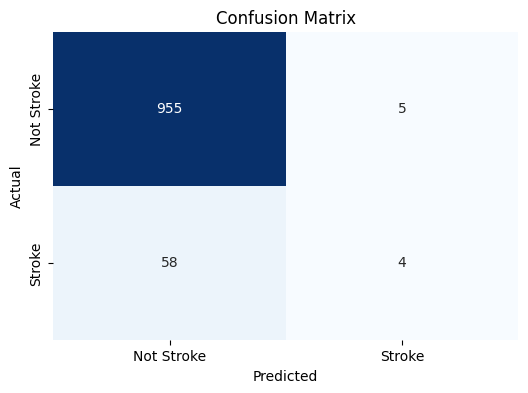


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.94      0.99      0.97       960
      Stroke       0.44      0.06      0.11        62

    accuracy                           0.94      1022
   macro avg       0.69      0.53      0.54      1022
weighted avg       0.91      0.94      0.92      1022

ROC-AUC: 0.8220766129032259


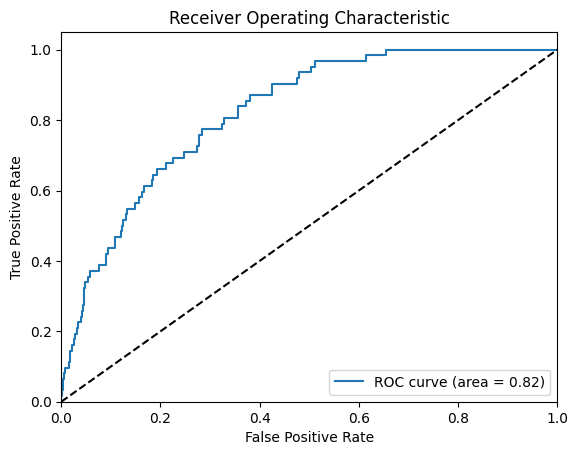

PR AUC: 0.24359399200791776


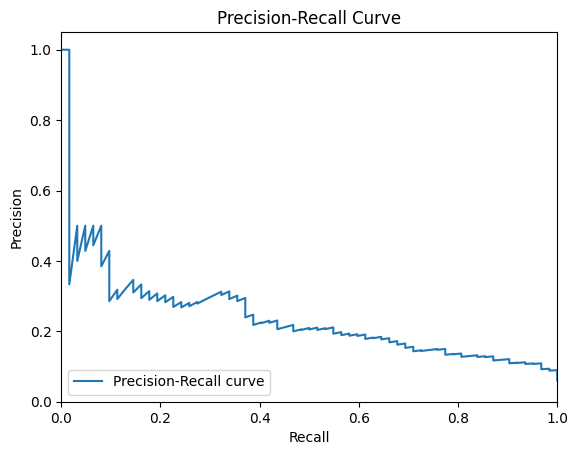

100%|██████████| 13/13 [00:26<00:00,  2.01s/it]


In [45]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)



    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [16:11:33] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[957   3]
 [ 59   3]]


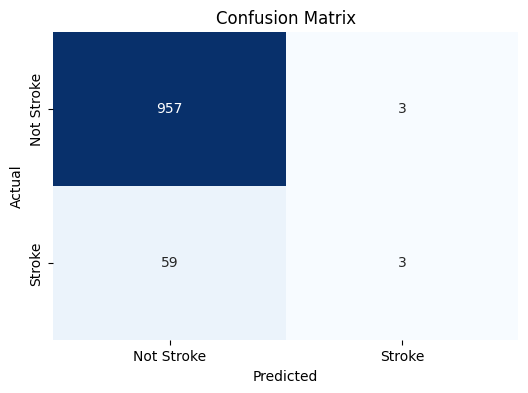


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.94      1.00      0.97       960
      Stroke       0.50      0.05      0.09        62

    accuracy                           0.94      1022
   macro avg       0.72      0.52      0.53      1022
weighted avg       0.92      0.94      0.92      1022

ROC-AUC: 0.8470094086021506


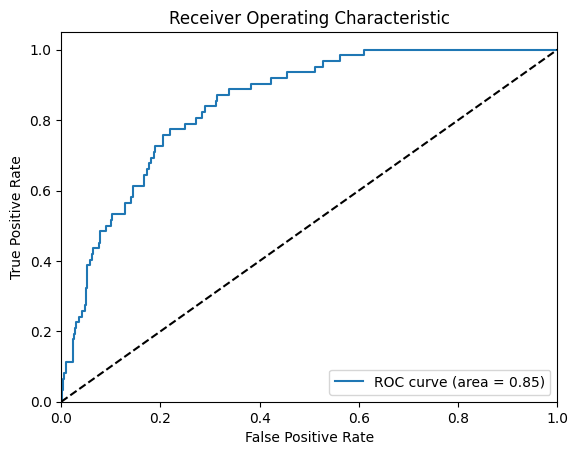

PR AUC: 0.2589531615292957


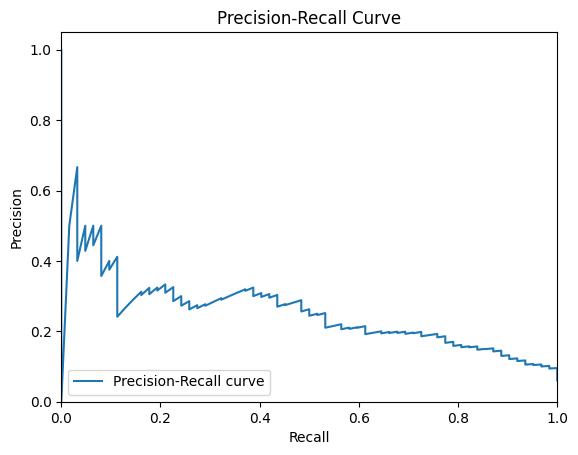

In [46]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft" # voting='hard' / voting='soft', weights=[2, 1, 2,1]
)

voting_model.fit(X_train, y_train)
voting_train_pred = voting_model.predict(X_train)
voting_test_pred = voting_model.predict(X_test)


cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = voting_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred),
    "Test Precision": precision_score(y_test, voting_test_pred),
    "Train Recall": recall_score(y_train, voting_train_pred),
    "Test Recall": recall_score(y_test, voting_test_pred),
    "Train F1 Score": f1_score(y_train, voting_train_pred),
    "Test F1 Score": f1_score(y_test, voting_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [16:12:21] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "max_iter" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[940  20]
 [ 59   3]]


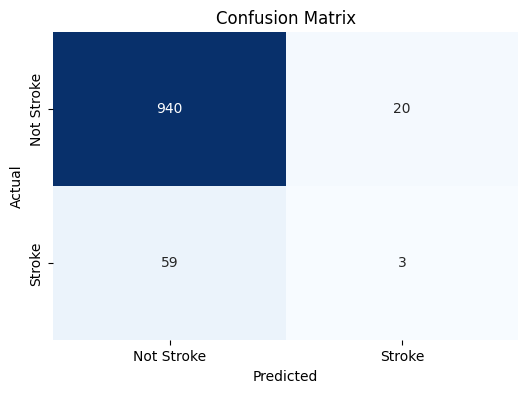


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.94      0.98      0.96       960
      Stroke       0.13      0.05      0.07        62

    accuracy                           0.92      1022
   macro avg       0.54      0.51      0.52      1022
weighted avg       0.89      0.92      0.91      1022

ROC-AUC: 0.7619287634408601


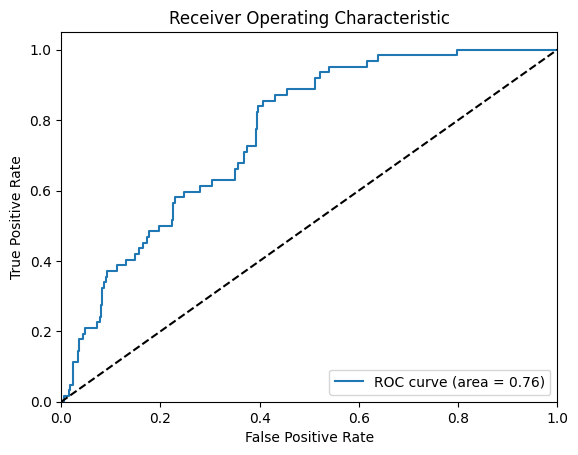

PR AUC: 0.1477801450494498


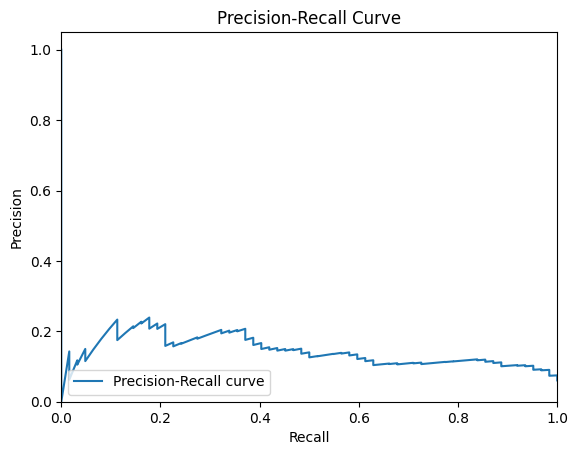

In [47]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),


    ],
    final_estimator=XGBClassifier(max_iter=2000),
    stack_method="predict_proba",   # best for classification usually
    n_jobs=-1
)

# Train
stack_auto.fit(X_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(X_train)
stack_auto_test_pred  = stack_auto.predict(X_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = stack_auto.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier "] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred),
    "Test Precision": precision_score(y_test, stack_auto_test_pred),
    "Train Recall": recall_score(y_train, stack_auto_train_pred),
    "Test Recall": recall_score(y_test, stack_auto_test_pred),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [48]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)

<Axes: >

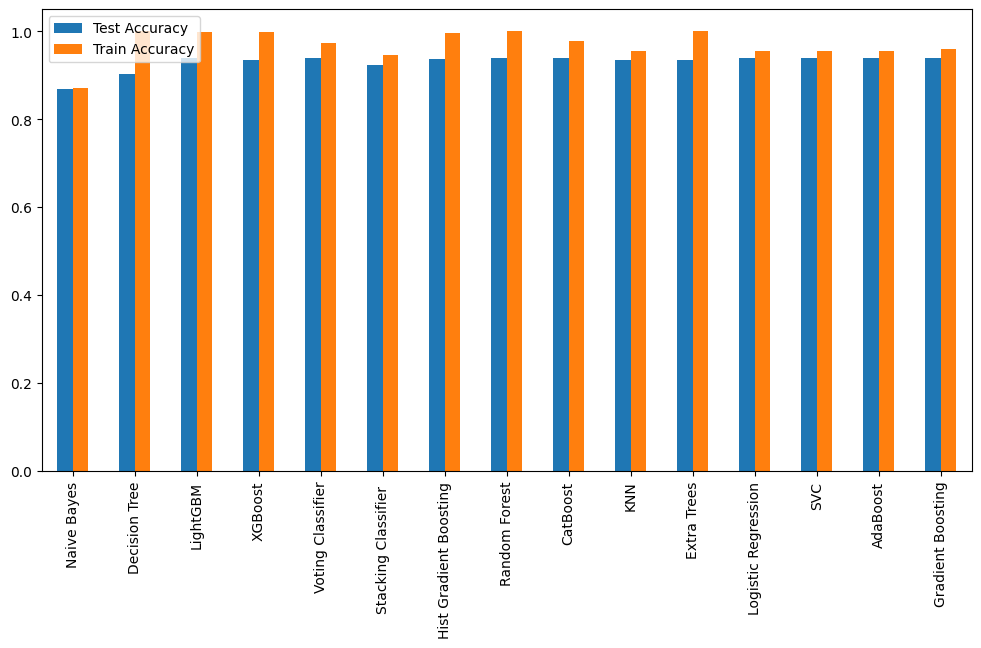

In [49]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

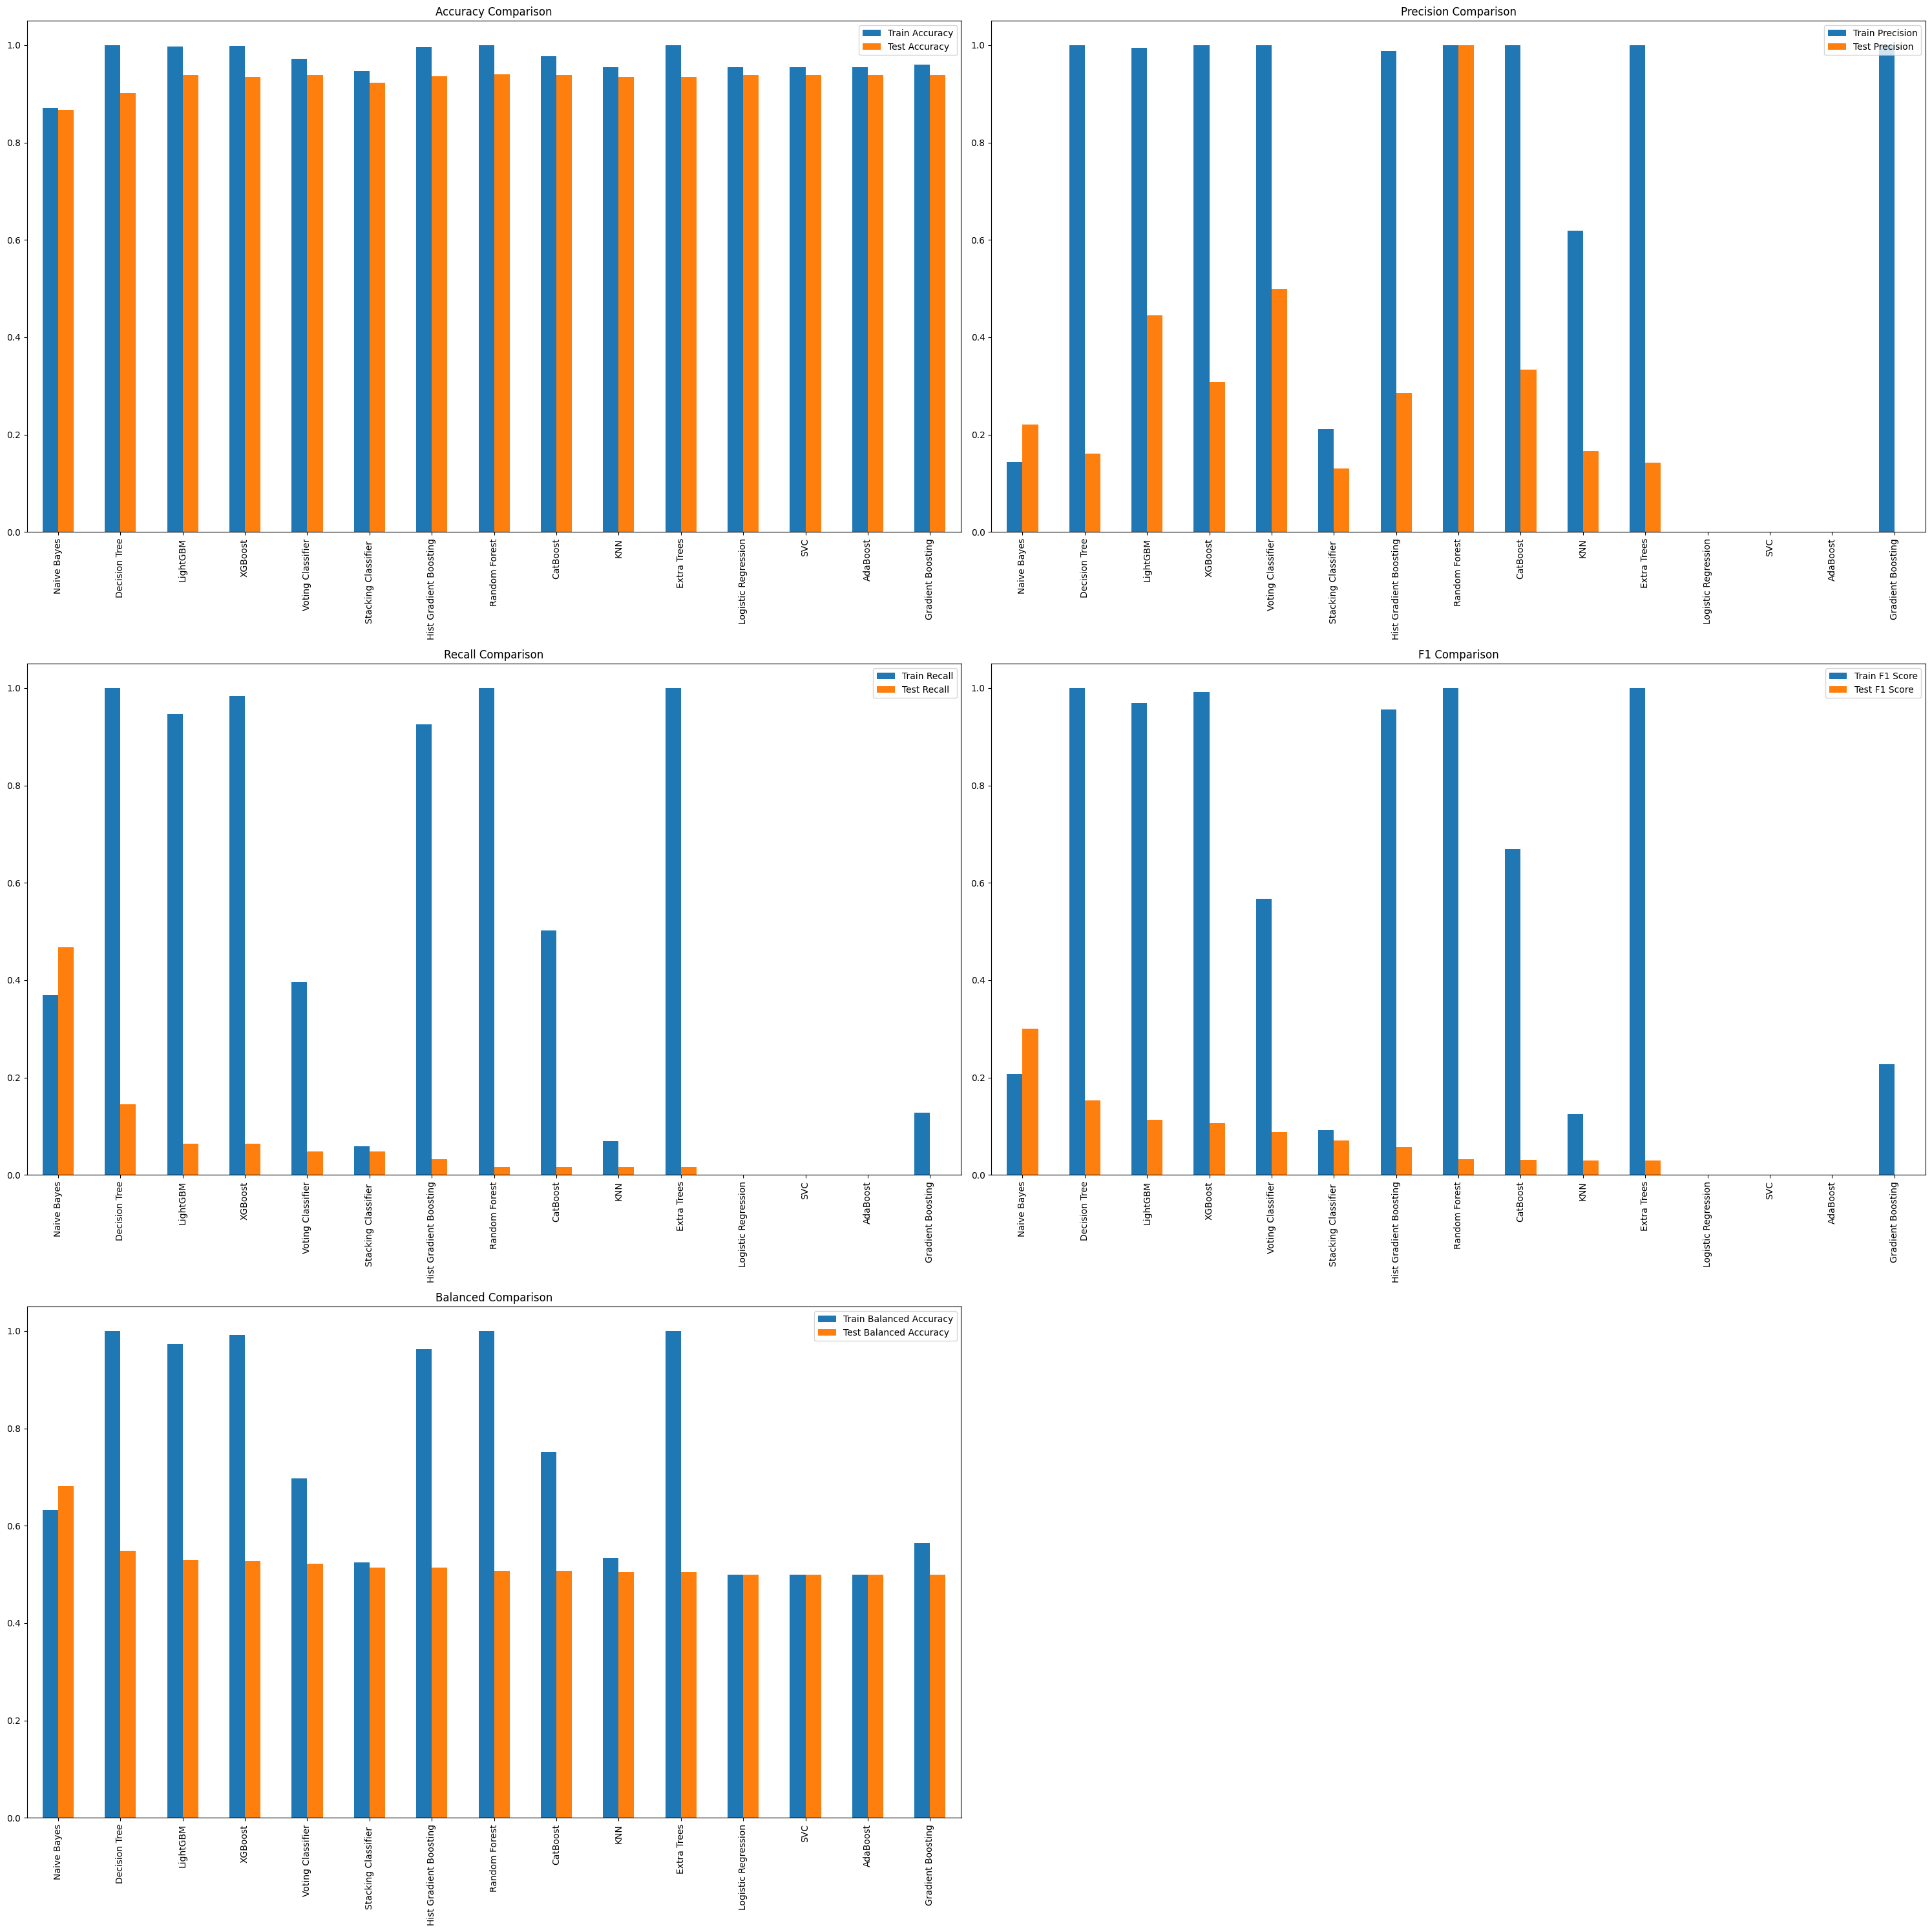

In [50]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)
    results_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()